# Avance 4. Modelos alternativos
### Proyecto Integrador — Equipo 11 · Cloud Copilot (Google Cloud GSD LATAM)
**Integrantes:** Edgar Iván Ramírez (A01797108), Jorge Muñoz Estrada (A01213938) y Juan Pablo Carvajal (A01796843)

**Contexto.** El proyecto (Avance 0) busca un flujo agéntico "Video-to-Document" con Gemini que procese las sesiones grabadas con clientes de GSD LATAM y genere borradores de *Technical Design Documents* (TDD) y slides de cierre. El Agente Analista debe localizar en la transcripción los **requisitos**, las **decisiones de arquitectura** y los **siguientes pasos**, y distinguirlos de la discusión técnica que no constituye un acuerdo.

**De dónde partimos.** En el Avance 3 construimos un baseline de Machine Learning clásico (Random Forest) para clasificar segmentos de transcripción en cinco categorías. Obtuvo un F1-Macro de ≈0.46, por encima del azar (≈0.12) pero lejos de la meta de negocio de **F1-Macro ≥ 0.70**, y el diagnóstico indicó sobreajuste por falta de datos. El Avance 3 concluyó que la siguiente etapa debía apoyarse en un modelo fundacional (Gemini, *zero/few-shot*) y compararse contra estos valores con la misma metodología.

**Pregunta de este avance.** Antes de pasar a Gemini, ¿puede algún algoritmo clásico distinto, con ajuste de hiperparámetros, acercarse a la meta? Para responderla:
1. Comparamos **seis modelos individuales** (sin ensambles) frente al azar y al baseline del Avance 3.
2. Ajustamos los **dos mejores** con una búsqueda aleatoria amplia y medimos la mejora con **validación cruzada anidada**, para no confundir ganancia real con selección favorable.
3. Elegimos el **modelo individual final** combinando la métrica con criterios del proyecto: detección de decisiones de arquitectura, estabilidad entre sesiones e interpretabilidad.
4. Analizamos sus errores por categoría y el **efecto de plantilla** del corpus sintético.

**Observaciones del Avance 2 que atendemos aquí:** (a) todas las particiones respetan la agrupación por sesión; (b) se controla explícitamente el efecto de las plantillas (sección 4.2); (c) no se usan pruebas chi² en este avance, por lo que la observación sobre celdas con frecuencia esperada menor a 5 no aplica a estos resultados.

## 0. ¿Por qué modelos clásicos si el proyecto usa Gemini?

El sistema propuesto en el Avance 0 se basa en Gemini, y este avance no cambia esa decisión. Comparamos modelos clásicos por cuatro razones ligadas al proyecto, no solo porque la actividad lo pida:

1. **La clasificación es la parte medible del Agente Analista.** Antes de redactar el TDD, el agente debe decidir si un fragmento de la reunión es un requisito, una decisión de arquitectura, un siguiente paso o solo discusión técnica. Esa tarea tiene etiquetas y una métrica objetiva (F1-Macro), a diferencia de la calidad global del documento.
2. **Sin una referencia barata no se puede demostrar el valor de Gemini.** Gemini implica costo por llamada, latencia y dependencia de un servicio externo. Para justificarlo hay que mostrar cuánto supera a la mejor alternativa sencilla, evaluada con las mismas particiones. Este avance construye esa referencia de la forma más fuerte posible: seis algoritmos y ajuste amplio de hiperparámetros, no un solo modelo sin ajustar.
3. **Indica dónde tiene que aportar Gemini.** El análisis por categoría y por similitud con el entrenamiento (sección 4) muestra en qué segmentos fallan los modelos clásicos: decisiones de arquitectura y formulaciones nuevas.
4. **Puede tener un papel en el flujo.** Un clasificador que entrena en milisegundos puede servir como verificación de respaldo: marcar para revisión humana los segmentos donde Gemini y el clasificador no coinciden.


## 1. Datos y limpieza (idéntica al Avance 3)

Usamos `datos_preprocesados_avance2.csv`, la salida del Avance 2 (139 segmentos de 30 sesiones sintéticas). Aplicamos **exactamente la misma limpieza que el Avance 3** para que los resultados sean comparables con su baseline:

- **Filas de relleno (27):** textos "Discusión técnica sobre el segmento N", sin contenido técnico, que el Avance 2 identificó como efecto de lote (otra plantilla, otro idioma y solo dos categorías). No permiten aprender la etiqueta.
- **Frases duplicadas (36):** la misma frase aparece en varias sesiones con la misma etiqueta. El Avance 3 (sección 3.6) demostró que mantenerlas infla la métrica, porque una copia queda en entrenamiento y otra en validación y el modelo acierta por memoria.

Quedan **76 segmentos únicos de 25 sesiones**. La variable objetivo es `expected_category`. Las entradas son `text_clean` y, como opción que se evalúa en el ajuste, cuatro metadatos numéricos (`segment_duration_sec`, `word_count`, `avg_word_length`, `num_speakers`). `session_id` solo se usa para agrupar.

In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier  # solo para reproducir el baseline del Avance 3
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning, UndefinedMetricWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)
# En algunos folds internos de la búsqueda anidada architecture_decision tiene solo 2-3 ejemplos (< 4 folds);
# scikit-learn lo advierte en cada búsqueda. Se documenta en la sección 3 y se omite el aviso repetido.
warnings.filterwarnings('ignore', message='The least populated class')
os.environ['PYTHONWARNINGS'] = 'ignore'  # los procesos paralelos de joblib no heredan los filtros anteriores
SEED = 42
pd.set_option('display.max_colwidth', 120)
print('scikit-learn:', sklearn.__version__)

# El CSV es la salida del Avance 2 (misma entrada que el Avance 3).
candidatos_csv = [Path('datos_preprocesados_avance2.csv'),
                  Path('../Avance3/datos_preprocesados_avance2.csv'),
                  Path('Documentación/Avance3/datos_preprocesados_avance2.csv')]
csv_path = next((p for p in candidatos_csv if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError('Coloca datos_preprocesados_avance2.csv junto al notebook (está en Documentación/Avance3/).')

df = pd.read_csv(csv_path)
num_features = ['segment_duration_sec', 'word_count', 'avg_word_length', 'num_speakers']
requeridas = ['session_id', 'text_clean', 'expected_category', *num_features]
faltantes = sorted(set(requeridas) - set(df.columns))
if faltantes:
    raise ValueError(f'Faltan columnas: {faltantes}')
df['text_clean'] = df['text_clean'].fillna('').astype(str)
df['session_id'] = df['session_id'].astype(str)

# Misma limpieza que el Avance 3 (sección 1.1 y 1.2):
# 1) filas de relleno en español sin contenido real (efecto de lote identificado en el Avance 2)
# 2) frases duplicadas entre sesiones (el Avance 3 demostró que inflan la métrica por memorización)
es_relleno = df['text_clean'].str.startswith('Discusión técnica sobre el segmento')
sin_relleno = df[~es_relleno]
df_modelo = sin_relleno.drop_duplicates(subset='text_clean', keep='first').reset_index(drop=True)

assert not df_modelo['text_clean'].str.startswith('Discusión técnica sobre el segmento').any()
assert not df_modelo['text_clean'].duplicated().any()

display(pd.DataFrame({
    'Paso': ['Segmentos del Avance 2', 'Filas de relleno excluidas', 'Frases duplicadas excluidas', 'Segmentos únicos para modelar'],
    'Segmentos': [len(df), int(es_relleno.sum()), len(sin_relleno) - len(df_modelo), len(df_modelo)]
}))

X = df_modelo[['text_clean', *num_features]]
y = df_modelo['expected_category'].astype(str)
groups = df_modelo['session_id']
CLASES = sorted(y.unique())

distribucion = (df_modelo.groupby('expected_category')
                .agg(Segmentos=('segment_id', 'size'), Sesiones=('session_id', 'nunique'))
                .sort_values('Segmentos', ascending=False))
distribucion['%'] = (100 * distribucion['Segmentos'] / len(df_modelo)).round(1)
print(f'Sesiones: {groups.nunique()} | Clases: {len(CLASES)}')
display(distribucion)

scikit-learn: 1.6.1


,Paso,Segmentos
0,Segmentos del Avance 2,139
1,Filas de relleno excluidas,27
2,Frases duplicadas excluidas,36
3,Segmentos únicos para modelar,76


Sesiones: 25 | Clases: 5


,Segmentos,Sesiones,%
expected_category,,,
requirement,26,16,34.2
next_steps,23,13,30.3
database_migration,13,10,17.1
technical_discussion,9,9,11.8
architecture_decision,5,4,6.6


### 1.1 Esquema de evaluación y métricas

**Por qué no usamos una partición fija de prueba.** Con 76 segmentos, una partición de prueba del 20 % deja ≈12 segmentos de 3 a 5 sesiones. La partición del Avance 3 (`GroupShuffleSplit`, semilla 42) dejó en prueba 12 segmentos de solo tres categorías, **sin ninguna decisión de arquitectura ni discusión técnica**: justo las clases más importantes para el TDD no se podían evaluar. Por eso estimamos el desempeño con:

- **`StratifiedGroupKFold` de 5 folds repetido con tres semillas (15 particiones).** Agrupa por `session_id` (ningún segmento de una reunión está a la vez en entrenamiento y validación, como pidió la retroalimentación del Avance 2) y estratifica por categoría para que las clases minoritarias aparezcan en la mayoría de los folds.
- **Predicciones *out-of-fold*** de una repetición: cada segmento se predice exactamente una vez con un modelo que no vio su sesión. Con ellas medimos el desempeño por categoría sobre los 76 segmentos, incluidas las 5 decisiones de arquitectura.
- **Validación cruzada anidada** para el ajuste (sección 3).

**Métrica principal: F1-Macro**, la misma del Avance 3, porque da igual peso a todas las categorías y el corpus está desbalanceado (5 decisiones de arquitectura frente a 26 requisitos). La **meta de negocio F1-Macro ≥ 0.70** proviene del Avance 3 (sección 3.5): por debajo de ese nivel, al menos 3 de cada 10 segmentos irían a una sección equivocada del TDD y la corrección manual tomaría casi lo mismo que redactarlo. Métricas complementarias: Accuracy, Precision-Macro, Recall-Macro y tiempos de ajuste y predicción.

**Costo del error por categoría.** No todos los errores pesan igual en el TDD, por lo que añadimos métricas por categoría:

| Categoría | Destino en los entregables | Error más costoso | Métrica que lo vigila |
|---|---|---|---|
| `architecture_decision` | Sección de decisiones del TDD | Registrar como decisión algo que no se decidió (decisión inventada, contraria a la meta de *Faithfulness* > 90 %) | Precisión y recall de la clase |
| `requirement` | Requisitos del TDD (pregunta de negocio 1) | Omitir un requisito acordado con el cliente | Recall de la clase |
| `technical_discussion` | Contexto; no es un acuerdo | Confundirla con una decisión o un requisito | F1 de la clase |
| `next_steps` | Slides de cierre (pregunta de negocio 3) | Omisión | F1-Macro |
| `database_migration` | Alcance y arquitectura | Omisión | F1-Macro |

Nota: el F1-Macro por fold promedia las categorías presentes en cada fold de validación; el F1 por categoría se calcula con las predicciones *out-of-fold*.

In [3]:
# Esquema de evaluación: StratifiedGroupKFold (5 folds) repetido con tres semillas = 15 particiones.
# Agrupa por sesión (ningún segmento de una reunión queda en entrenamiento y validación a la vez)
# y estratifica por categoría para que las clases minoritarias aparezcan en la mayoría de los folds.
SEMILLAS_CV = [SEED, 7, 2026]
SPLITS = []
for s in SEMILLAS_CV:
    SPLITS += list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s).split(X, y, groups))
SPLITS_REP1 = SPLITS[:5]  # una repetición: cada segmento se predice exactamente una vez (predicciones out-of-fold)

for tr, te in SPLITS:
    assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[te])), 'Sesiones solapadas entre entrenamiento y validación'

presencia = pd.DataFrame([y.iloc[te].value_counts() for _, te in SPLITS]).reindex(columns=CLASES).fillna(0).astype(int)
presencia.index = [f'fold {i+1}' for i in range(len(SPLITS))]
print('Segmentos de cada categoría en cada fold de validación:')
display(presencia.T)

METRICAS = {'f1_macro': 'f1_macro', 'accuracy': 'accuracy',
            'precision_macro': 'precision_macro', 'recall_macro': 'recall_macro'}

def crear_preparacion(vocab_completo=True, usar_metadatos=False):
    """TF-IDF del texto y, opcionalmente, metadatos numéricos. Se ajusta dentro de cada fold."""
    if vocab_completo:   # configuración recomendada en la sección 3.6 del Avance 3
        texto = TfidfVectorizer(ngram_range=(1, 2), stop_words='english', sublinear_tf=True)
    else:                # configuración del baseline Random Forest del Avance 3
        texto = TfidfVectorizer(max_features=100, ngram_range=(1, 2), stop_words='english', max_df=0.85)
    numericas = (Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())])
                 if usar_metadatos else 'drop')
    return ColumnTransformer([('texto', texto, 'text_clean'), ('numericas', numericas, num_features)],
                             sparse_threshold=0.0)  # matriz densa para que GaussianNB use la misma representación

def crear_pipeline(estimador, **kw):
    return Pipeline([('preparacion', crear_preparacion(**kw)), ('modelo', estimador)])

def predicciones_oof(pipeline, splits=SPLITS_REP1):
    """Predicción de cada segmento con un modelo que no lo vio en entrenamiento."""
    pred = pd.Series(index=y.index, dtype=object)
    for tr, te in splits:
        modelo = clone(pipeline).fit(X.iloc[tr], y.iloc[tr])
        pred.iloc[te] = modelo.predict(X.iloc[te])
    return pred

def metricas_criticas(pred):
    """Métricas por categoría ligadas al TDD (ver tabla de costos de error)."""
    r = classification_report(y, pred, labels=CLASES, output_dict=True, zero_division=0)
    return {'Precisión decisión arq.': r['architecture_decision']['precision'],
            'Recall decisión arq.': r['architecture_decision']['recall'],
            'Recall requisitos': r['requirement']['recall'],
            'F1 discusión técnica': r['technical_discussion']['f1-score']}

Segmentos de cada categoría en cada fold de validación:


,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,fold 10,fold 11,fold 12,fold 13,fold 14,fold 15
expected_category,,,,,,,,,,,,,,,
architecture_decision,3,0,1,1,0,1,0,0,2,2,1,1,0,2,1
database_migration,1,3,1,5,3,1,1,5,3,3,1,3,0,4,5
next_steps,1,3,7,5,7,7,5,3,2,6,3,4,5,1,10
requirement,3,7,7,5,4,6,7,1,8,4,3,3,9,6,5
technical_discussion,0,3,2,0,4,3,2,2,1,1,0,3,2,1,3


## 2. Construcción y comparación de seis modelos individuales

Todos los modelos usan la misma representación inicial: **TF-IDF del texto con vocabulario completo, unigramas y bigramas y `sublinear_tf`**, la configuración que el Avance 3 (sección 3.6) encontró más adecuada para clasificar texto, sin metadatos (el Avance 3 mostró por importancia de permutación que `segment_duration_sec` y `num_speakers` no aportaban). El TF-IDF se ajusta dentro de cada fold mediante `Pipeline`, por lo que el vocabulario de validación nunca se usa para entrenar.

| Algoritmo | Familia | Por qué es relevante para clasificar segmentos de una sesión |
|---|---|---|
| Regresión Logística | Lineal | Referencia estándar en texto; sus coeficientes muestran qué términos llevan a cada sección del TDD (trazabilidad). |
| SVC (RBF) | Margen máximo | Separa clases con fronteras no lineales en espacios de alta dimensión como TF-IDF. |
| Árbol de Decisión | Árboles (individual) | Reglas legibles para el consultor, pero propenso a sobreajustar con 76 segmentos. |
| KNN | Distancias | Clasifica por parecido con segmentos ya etiquetados; sirve para medir cuánto depende el desempeño de frases parecidas (efecto de plantilla). |
| Naive Bayes (Gauss) | Probabilístico | Funciona con pocos datos y es barato; sus parámetros por clase se pueden inspeccionar. |
| Perceptrón Multicapa | Red neuronal | Puede capturar combinaciones de términos no lineales; es el más costoso de entrenar. |

`class_weight='balanced'` se aplica donde el algoritmo lo admite (Regresión Logística, SVC y Árbol); KNN, Naive Bayes y MLP no tienen ese parámetro en scikit-learn, lo que puede perjudicarlos en las clases minoritarias.

Como **referencias** (no cuentan entre los seis) se evalúan con el mismo esquema el clasificador al azar y el **Random Forest del Avance 3** con su configuración original (TF-IDF de 100 términos más metadatos).

Seis modelos individuales, ordenados por F1-Macro (15 particiones agrupadas por sesión):


,Modelo,F1-Macro (CV),Desv. F1,Accuracy (CV),Precision-Macro (CV),Recall-Macro (CV),Ajuste (ms/fold),Predicción (ms/fold),Precisión decisión arq.,Recall decisión arq.,Recall requisitos,F1 discusión técnica
1,Naive Bayes (Gauss),0.557,0.099,0.726,0.567,0.592,11.471,15.295,0.0,0.0,0.923,0.444
2,Regresión Logística,0.546,0.095,0.729,0.547,0.613,24.975,15.529,0.0,0.0,0.923,0.308
3,Perceptrón Multicapa,0.539,0.093,0.725,0.531,0.601,537.197,16.450,0.0,0.0,0.923,0.308
4,Árbol de Decisión,0.525,0.121,0.689,0.537,0.576,17.005,13.938,0.0,0.0,0.885,0.182
5,SVC (RBF),0.503,0.110,0.703,0.512,0.567,16.456,17.447,0.0,0.0,0.923,0.000
6,KNN,0.366,0.104,0.497,0.368,0.441,10.036,18.154,0.0,0.0,0.462,0.000


Referencias con el mismo esquema de evaluación (no cuentan entre los seis modelos):


,Modelo,F1-Macro (CV),Desv. F1,Accuracy (CV),Precision-Macro (CV),Recall-Macro (CV),Ajuste (ms/fold),Predicción (ms/fold),Precisión decisión arq.,Recall decisión arq.,Recall requisitos,F1 discusión técnica
0,Ref. azar (Dummy estratificado),0.126,0.048,0.231,0.135,0.147,10.701,15.902,0.000,0.0,0.538,0.133
1,Ref. baseline Avance 3 (Random Forest),0.541,0.132,0.643,0.574,0.575,278.129,31.320,0.667,0.4,0.808,0.200


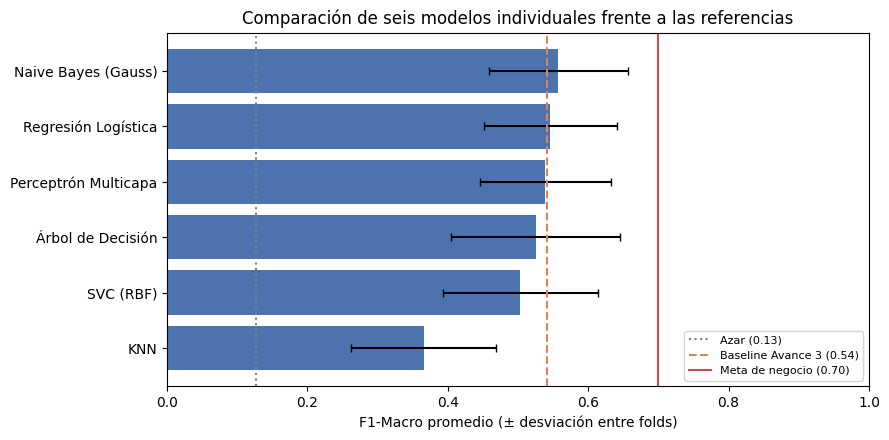

In [4]:
referencias = {
    'Ref. azar (Dummy estratificado)': crear_pipeline(DummyClassifier(strategy='stratified', random_state=SEED)),
    'Ref. baseline Avance 3 (Random Forest)': crear_pipeline(
        RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=SEED),
        vocab_completo=False, usar_metadatos=True),
}
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED),
    'SVC (RBF)': SVC(class_weight='balanced', random_state=SEED),
    'Árbol de Decisión': DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes (Gauss)': GaussianNB(),
    'Perceptrón Multicapa': MLPClassifier(hidden_layer_sizes=(40,), max_iter=1000, random_state=SEED),
}

scores_base = {}   # F1 por fold de cada modelo sin ajustar (se reutiliza para la comparación antes/después)
def evaluar(nombre, pipeline):
    r = cross_validate(pipeline, X, y, cv=SPLITS, scoring=METRICAS, n_jobs=-1)
    scores_base[nombre] = r['test_f1_macro']
    fila = {'Modelo': nombre,
            'F1-Macro (CV)': r['test_f1_macro'].mean(),
            'Desv. F1': r['test_f1_macro'].std(),
            'Accuracy (CV)': r['test_accuracy'].mean(),
            'Precision-Macro (CV)': r['test_precision_macro'].mean(),
            'Recall-Macro (CV)': r['test_recall_macro'].mean(),
            'Ajuste (ms/fold)': 1000 * r['fit_time'].mean(),
            'Predicción (ms/fold)': 1000 * r['score_time'].mean()}
    fila.update(metricas_criticas(predicciones_oof(pipeline)))
    return fila

df_ref = pd.DataFrame([evaluar(n, p) for n, p in referencias.items()])
df_results = (pd.DataFrame([evaluar(n, crear_pipeline(m)) for n, m in modelos.items()])
              .sort_values('F1-Macro (CV)', ascending=False).reset_index(drop=True))
df_results.index = df_results.index + 1

F1_AZAR = df_ref.loc[0, 'F1-Macro (CV)']
F1_BASELINE = df_ref.loc[1, 'F1-Macro (CV)']
META_NEGOCIO = 0.70  # definida en el Avance 3, sección 3.5

print(f'Seis modelos individuales, ordenados por F1-Macro ({len(SPLITS)} particiones agrupadas por sesión):')
display(df_results.round(3))
print('Referencias con el mismo esquema de evaluación (no cuentan entre los seis modelos):')
display(df_ref.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
orden = df_results.iloc[::-1]
ax.barh(orden['Modelo'], orden['F1-Macro (CV)'], xerr=orden['Desv. F1'], capsize=3, color='#4C72B0')
ax.axvline(F1_AZAR, color='gray', ls=':', label=f'Azar ({F1_AZAR:.2f})')
ax.axvline(F1_BASELINE, color='#DD8452', ls='--', label=f'Baseline Avance 3 ({F1_BASELINE:.2f})')
ax.axvline(META_NEGOCIO, color='#C44E52', ls='-', label=f'Meta de negocio ({META_NEGOCIO:.2f})')
ax.set(xlim=(0, 1), xlabel='F1-Macro promedio (± desviación entre folds)',
       title='Comparación de seis modelos individuales frente a las referencias')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

### 2.1 Interpretación de la comparación inicial

*(Valores de la ejecución guardada con scikit-learn 1.6.1.)*

- **Cinco de los seis modelos quedan en el mismo rango que el baseline del Avance 3.** Naive Bayes (0.557 ± 0.099), Regresión Logística (0.546 ± 0.095), MLP (0.539 ± 0.093), Árbol (0.525 ± 0.121) y SVC (0.503 ± 0.110) quedan a menos de una desviación estándar entre sí y del Random Forest de referencia (0.541 ± 0.132). Con 76 segmentos, el orden entre ellos **no es robusto**: una diferencia de 0.01–0.05 es menor que la variabilidad entre folds. KNN (0.366) queda claramente por debajo: con frases cortas, el vecino más cercano depende más del vocabulario compartido que de la intención del segmento.
- **Ninguno se acerca a la meta de 0.70.** Todos superan con claridad al azar (0.126), lo que confirma que el texto contiene señal, pero el límite que observó el Avance 3 se mantiene al cambiar de algoritmo.
- **Hallazgo crítico para el TDD:** ninguno de los seis modelos sin ajustar identifica correctamente una sola **decisión de arquitectura** (precisión y recall de 0 en las predicciones *out-of-fold*). Con 5 ejemplos de 4 sesiones, la clase más importante para la sección de decisiones del TDD no se aprende. En cambio, el recall de **requisitos** es alto (≈0.92) en casi todos.
- **Costo computacional:** todos entrenan en milisegundos; el MLP es entre 20 y 40 veces más lento que el resto (≈200 ms por fold) sin ventaja en F1. Frente al presupuesto de menos de 5 minutos por borrador (Avance 0), ninguno es un cuello de botella.

Los dos modelos con mayor F1-Macro promedio, **Naive Bayes (Gauss)** y **Regresión Logística**, pasan al ajuste fino, como indica la actividad. Dado que el MLP queda a 0.007 de la Regresión Logística, también registramos su espacio de búsqueda (arquitectura, activación y tasa de aprendizaje) en el código, aunque no fue seleccionado.

## 3. Ajuste de hiperparámetros de los dos mejores modelos

**Método.** `RandomizedSearchCV` explora en cada modelo un espacio que combina los hiperparámetros del algoritmo con los de la **representación del texto**, porque el Avance 3 mostró que el tamaño del vocabulario cambia el desempeño:

| Componente | Hiperparámetros explorados |
|---|---|
| TF-IDF y metadatos (común) | tamaño del vocabulario (100, 300 o completo), unigramas o unigramas + bigramas, `sublinear_tf`, `min_df` e inclusión o no de los cuatro metadatos |
| Naive Bayes (Gauss) | `var_smoothing` en escala logarítmica entre 1e-12 y 1 |
| Regresión Logística | `C` en escala logarítmica entre 0.01 y 1000, `solver` y `class_weight` |
| MLP (definido, no seleccionado) | arquitectura (6 opciones de 1 y 2 capas), activación, *solver*, tasa de aprendizaje y regularización L2 |

**Por qué validación anidada.** Si se prueban 100 configuraciones con los mismos 76 segmentos, la mejor parecerá buena en parte por azar (sesgo de selección). Para medir la mejora real:

1. En cada una de las **15 particiones externas**, la búsqueda (60 configuraciones × 4 folds internos agrupados por sesión) usa solo el entrenamiento de esa partición.
2. La configuración ganadora se evalúa en la validación externa, que la búsqueda nunca vio.
3. Comparamos fold por fold contra el mismo modelo sin ajustar en **las mismas 15 particiones**.

En algunos folds internos `architecture_decision` queda con solo 2 o 3 ejemplos, menos que los 4 folds internos; scikit-learn lo advierte y omitimos el aviso repetido, pero es otra expresión del límite de datos en la clase más importante.

Después, una **búsqueda final de 100 configuraciones** con los 76 segmentos define la configuración que pasa al siguiente avance.

In [5]:
top_2_names = df_results['Modelo'].head(2).tolist()
print('Candidatos para el ajuste fino:', top_2_names)

# Espacio común de representación: se ajusta junto con el modelo porque el Avance 3 mostró que
# el tamaño del vocabulario y los metadatos cambian el desempeño.
ESPACIO_PREP = {
    'preparacion__texto__max_features': [100, 300, None],
    'preparacion__texto__ngram_range': [(1, 1), (1, 2)],
    'preparacion__texto__sublinear_tf': [True, False],
    'preparacion__texto__min_df': [1, 2],
    'preparacion__numericas': ['drop', Pipeline([('imputar', SimpleImputer(strategy='median')),
                                                 ('escalar', StandardScaler())])],
}
# Rejillas discretas en escala logarítmica (en lugar de distribuciones de scipy) para que el muestreo
# de RandomizedSearchCV sea idéntico en cualquier versión de scipy (p. ej., local y Colab).
def LOG(desde, hasta, n):
    return [float(v) for v in np.logspace(desde, hasta, n)]

ESPACIOS = {
    'Regresión Logística': {'modelo__C': LOG(-2, 3, 26), 'modelo__solver': ['lbfgs', 'liblinear'],
                            'modelo__class_weight': ['balanced', None]},
    'SVC (RBF)': {'modelo__C': LOG(-2, 3, 26), 'modelo__kernel': ['linear', 'rbf'],
                  'modelo__gamma': ['scale', 'auto']},
    'Árbol de Decisión': {'modelo__criterion': ['gini', 'entropy'], 'modelo__max_depth': [3, 5, 8, 12, None],
                          'modelo__min_samples_leaf': [1, 2, 3, 4, 5], 'modelo__ccp_alpha': [0.0, 0.005, 0.01, 0.02]},
    'KNN': {'modelo__n_neighbors': list(range(1, 16)), 'modelo__weights': ['uniform', 'distance'],
            'modelo__metric': ['euclidean', 'cosine']},
    'Naive Bayes (Gauss)': {'modelo__var_smoothing': LOG(-12, 0, 49)},
    'Perceptrón Multicapa': {
        'modelo__hidden_layer_sizes': [(20,), (40,), (100,), (200,), (40, 20), (100, 50)],  # arquitectura
        'modelo__activation': ['relu', 'tanh', 'logistic'],                                 # función de activación
        'modelo__solver': ['adam', 'lbfgs'],
        'modelo__learning_rate_init': LOG(-4, -1, 13),                               # tasa de aprendizaje
        'modelo__alpha': LOG(-6, -1, 21)},                                           # regularización L2
}
N_ITER_ANIDADO = 60   # configuraciones por fold externo
N_ITER_FINAL = 100    # configuraciones en la búsqueda final con los 76 segmentos

def crear_busqueda(nombre, n_iter, semilla):
    return RandomizedSearchCV(crear_pipeline(modelos[nombre]), {**ESPACIO_PREP, **ESPACIOS[nombre]},
                              n_iter=n_iter, scoring='f1_macro',
                              cv=StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED),
                              refit=True, random_state=semilla, n_jobs=-1, error_score='raise')

for nombre in top_2_names:
    print(f"{nombre}: {len({**ESPACIO_PREP, **ESPACIOS[nombre]})} hiperparámetros en el espacio de búsqueda")

Candidatos para el ajuste fino: ['Naive Bayes (Gauss)', 'Regresión Logística']
Naive Bayes (Gauss): 6 hiperparámetros en el espacio de búsqueda
Regresión Logística: 8 hiperparámetros en el espacio de búsqueda


Tiempo de la búsqueda anidada: 1.6 min (2 modelos × 15 folds × 60 configuraciones × 4 folds internos)


,Modelo,F1 sin ajustar,Desv. sin ajustar,F1 ajustado (CV anidada),Desv. ajustado,Mejora,Folds que mejoran
0,Naive Bayes (Gauss),0.557,0.099,0.605,0.138,0.048,8 de 15
1,Regresión Logística,0.546,0.095,0.561,0.142,0.015,6 de 15


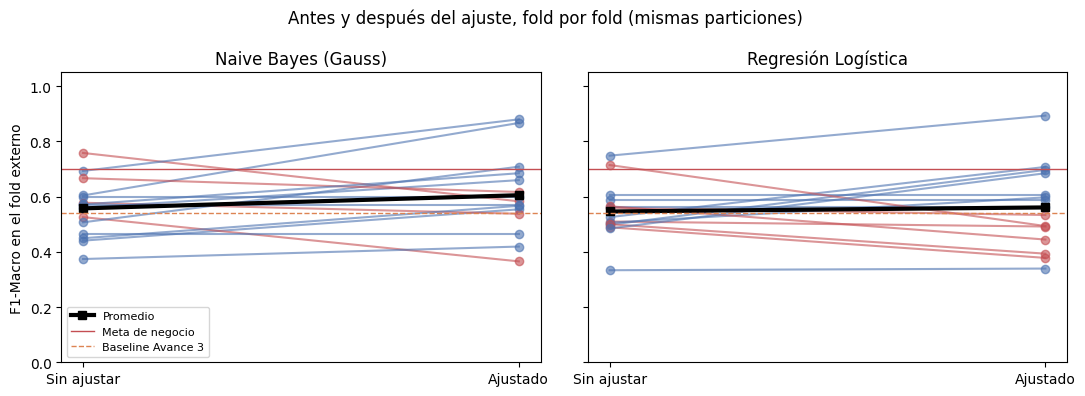

In [6]:
# Validación cruzada anidada: en cada una de las 15 particiones externas, RandomizedSearchCV busca la
# mejor configuración usando SOLO el entrenamiento de esa partición (4 folds internos agrupados por sesión)
# y el resultado se mide en la validación externa, que la búsqueda nunca vio.
inicio = time.time()
resultados_anidados = {}
for nombre in top_2_names:
    f1_folds, mejores, pred_oof = [], [], pd.Series(index=y.index, dtype=object)
    for i, (tr, te) in enumerate(SPLITS):
        b = crear_busqueda(nombre, N_ITER_ANIDADO, SEED + i)
        b.fit(X.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])
        pred = b.predict(X.iloc[te])
        f1_folds.append(f1_score(y.iloc[te], pred, average='macro'))
        mejores.append(b.best_params_)
        if i < len(SPLITS_REP1):
            pred_oof.iloc[te] = pred
    resultados_anidados[nombre] = {'f1': np.array(f1_folds), 'params': mejores, 'oof': pred_oof}
print(f'Tiempo de la búsqueda anidada: {(time.time() - inicio) / 60:.1f} min '
      f'({len(top_2_names)} modelos × {len(SPLITS)} folds × {N_ITER_ANIDADO} configuraciones × 4 folds internos)')

filas = []
for nombre in top_2_names:
    antes, despues = scores_base[nombre], resultados_anidados[nombre]['f1']
    filas.append({'Modelo': nombre,
                  'F1 sin ajustar': antes.mean(), 'Desv. sin ajustar': antes.std(),
                  'F1 ajustado (CV anidada)': despues.mean(), 'Desv. ajustado': despues.std(),
                  'Mejora': despues.mean() - antes.mean(),
                  'Folds que mejoran': f'{int((despues > antes).sum())} de {len(SPLITS)}'})
df_antes_despues = pd.DataFrame(filas)
display(df_antes_despues.round(3))

fig, axes = plt.subplots(1, len(top_2_names), figsize=(11, 4), sharey=True)
for ax, nombre in zip(np.atleast_1d(axes), top_2_names):
    antes, despues = scores_base[nombre], resultados_anidados[nombre]['f1']
    for a, d in zip(antes, despues):
        ax.plot([0, 1], [a, d], color='#4C72B0' if d >= a else '#C44E52', alpha=0.6, marker='o')
    ax.plot([0, 1], [antes.mean(), despues.mean()], color='black', lw=3, marker='s', label='Promedio')
    ax.axhline(META_NEGOCIO, color='#C44E52', ls='-', lw=1, label='Meta de negocio')
    ax.axhline(F1_BASELINE, color='#DD8452', ls='--', lw=1, label='Baseline Avance 3')
    ax.set(xticks=[0, 1], xticklabels=['Sin ajustar', 'Ajustado'], title=nombre, ylim=(0, 1.05))
axes[0].set_ylabel('F1-Macro en el fold externo')
axes[0].legend(fontsize=8, loc='lower left')
plt.suptitle('Antes y después del ajuste, fold por fold (mismas particiones)')
plt.tight_layout()
plt.show()


Naive Bayes (Gauss): 5 mejores de 100 configuraciones


,F1 (CV interna),Desv.,texto__sublinear_tf,texto__ngram_range,texto__min_df,texto__max_features,numericas,var_smoothing
4,0.6614,0.1023,False,"(1, 2)",1,300,con metadatos,0.0056
0,0.5689,0.1174,True,"(1, 1)",1,None,con metadatos,0.0100
8,0.5689,0.1174,True,"(1, 1)",1,300,con metadatos,0.0100
71,0.5632,0.1391,False,"(1, 2)",1,300,con metadatos,0.0000
98,0.5632,0.1391,True,"(1, 2)",1,300,con metadatos,0.0006



Regresión Logística: 5 mejores de 100 configuraciones


,F1 (CV interna),Desv.,texto__sublinear_tf,texto__ngram_range,texto__min_df,texto__max_features,numericas,solver,class_weight,C
73,0.6190,0.0961,False,"(1, 2)",2,300,con metadatos,liblinear,balanced,25.1189
19,0.6185,0.0968,False,"(1, 2)",2,None,con metadatos,liblinear,balanced,15.8489
72,0.6061,0.0944,False,"(1, 2)",2,300,con metadatos,lbfgs,balanced,1000.0000
49,0.5936,0.1335,True,"(1, 2)",1,300,sin metadatos,lbfgs,balanced,0.0398
48,0.5796,0.0980,False,"(1, 2)",2,300,sin metadatos,liblinear,None,398.1072



Ganancia aparente frente a ganancia estimada fuera de la búsqueda:


,Modelo,F1 configuración inicial (CV de la búsqueda),Mejor F1 de la búsqueda (optimista),"F1 ajustado (CV anidada, honesto)"
0,Naive Bayes (Gauss),0.527,0.661,0.605
1,Regresión Logística,0.445,0.619,0.561


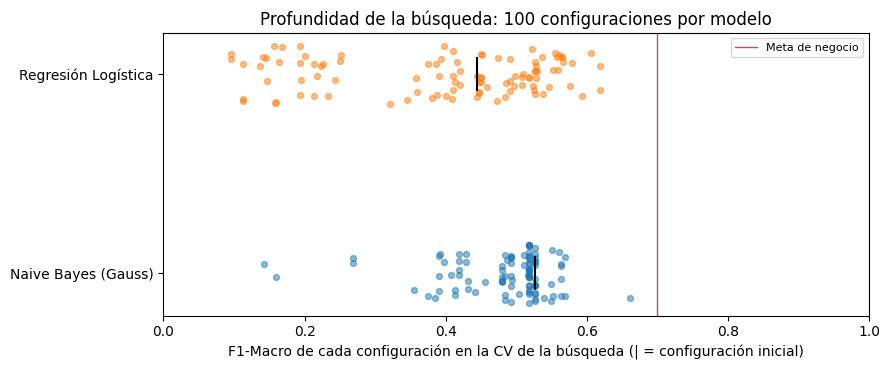

In [7]:
# Búsqueda final con los 76 segmentos: define la configuración que pasa al Avance 5.
# Su mejor puntaje es optimista (se eligió entre muchas configuraciones con los mismos datos);
# la estimación honesta del desempeño es la de la validación anidada.
busquedas_finales, top_configs, comparacion_busqueda = {}, [], []
for nombre in top_2_names:
    b = crear_busqueda(nombre, N_ITER_FINAL, SEED)
    b.fit(X, y, groups=groups)
    busquedas_finales[nombre] = b
    inicial = cross_validate(crear_pipeline(modelos[nombre]), X, y, groups=groups, cv=b.cv, scoring='f1_macro')['test_score'].mean()
    comparacion_busqueda.append({'Modelo': nombre, 'F1 configuración inicial (CV de la búsqueda)': inicial,
                                 'Mejor F1 de la búsqueda (optimista)': b.best_score_,
                                 'F1 ajustado (CV anidada, honesto)': resultados_anidados[nombre]['f1'].mean()})
    res = pd.DataFrame(b.cv_results_).sort_values('rank_test_score')
    cols = [c for c in res.columns if c.startswith('param_')]
    t = res.head(5)[['mean_test_score', 'std_test_score', *cols]].copy()
    t.columns = ['F1 (CV interna)', 'Desv.'] + [c.replace('param_preparacion__', '').replace('param_modelo__', '') for c in cols]
    t['numericas'] = t['numericas'].map(lambda v: 'sin metadatos' if isinstance(v, str) else 'con metadatos')
    t.insert(0, 'Modelo', nombre)
    top_configs.append(t)
    print(f'\n{nombre}: 5 mejores de {N_ITER_FINAL} configuraciones')
    display(t.drop(columns='Modelo').round(4))

print('\nGanancia aparente frente a ganancia estimada fuera de la búsqueda:')
display(pd.DataFrame(comparacion_busqueda).round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
for i, nombre in enumerate(top_2_names):
    s = busquedas_finales[nombre].cv_results_['mean_test_score']
    ax.scatter(s, np.full(len(s), i) + np.random.default_rng(SEED).uniform(-0.15, 0.15, len(s)), alpha=0.5, s=18)
    ax.scatter(comparacion_busqueda[i]['F1 configuración inicial (CV de la búsqueda)'], i, marker='|', s=600, color='black')
ax.axvline(META_NEGOCIO, color='#C44E52', lw=1, label='Meta de negocio')
ax.set(yticks=range(len(top_2_names)), yticklabels=top_2_names, xlim=(0, 1),
       xlabel='F1-Macro de cada configuración en la CV de la búsqueda (| = configuración inicial)',
       title=f'Profundidad de la búsqueda: {N_ITER_FINAL} configuraciones por modelo')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.1 Interpretación del ajuste

- **Naive Bayes mejora con el ajuste:** de 0.557 a **0.605** en validación anidada (+0.048, mejora en 8 de 15 folds). Su configuración final suaviza más la varianza (`var_smoothing` ≈ 0.0056), limita el vocabulario a 300 términos con unigramas y bigramas e incluye los metadatos. La mejora es moderada y su desviación aumenta (0.138), así que no garantiza el mismo efecto en sesiones nuevas.
- **La Regresión Logística mejora poco:** pasa de 0.546 a 0.561 (+0.015, mejora en 6 de 15 folds). Las mejores configuraciones usan `C` alto (≈15–25), `class_weight='balanced'`, 300 términos y metadatos, pero la ganancia es menor que la variabilidad entre folds.
- **Ganancia aparente frente a ganancia real.** Dentro de la búsqueda final, la mejor configuración parece subir de 0.527 a 0.661 en Naive Bayes y de 0.445 a 0.619 en Regresión Logística. Esa diferencia es optimista: la validación anidada muestra que la mejora fuera de la búsqueda es mucho menor. Reportar solo el mejor puntaje de `GridSearchCV`/`RandomizedSearchCV` habría sobrestimado el resultado en ≈0.06 puntos en ambos modelos.
- **Profundidad de la búsqueda:** 100 configuraciones por modelo en la búsqueda final y 900 en la anidada (15 × 60), sobre 6 a 8 hiperparámetros. La nube de puntos muestra que buena parte del espacio queda por debajo de la configuración inicial y que, en Naive Bayes, el máximo es un punto aislado sobre el grupo: parte de su ventaja es azar de selección, como confirma la validación anidada.
- **Lectura para el proyecto:** el ajuste confirma el diagnóstico del Avance 3. El techo no está en los hiperparámetros sino en la cantidad y diversidad de ejemplos etiquetados, sobre todo en las clases minoritarias.

## 4. Selección del modelo individual final

**Regla de decisión (definida antes de ver los resultados de esta sección):**
1. Si un candidato supera al otro en F1-Macro anidado por más que la mayor desviación entre folds, se elige ese candidato.
2. Si la diferencia es menor, la métrica no permite distinguirlos y se desempata con criterios del proyecto, en este orden:
   - **precisión en `architecture_decision`**, porque una decisión inventada en el TDD contradice la meta de fidelidad;
   - **interpretabilidad**, porque el consultor debe poder auditar por qué un segmento se clasificó así;
   - **menor variabilidad entre sesiones**.

El tiempo de ajuste y de predicción se reporta, pero no decide: todos los candidatos operan en milisegundos.

In [8]:
# Comparación de los dos modelos ajustados con criterios de métrica y de proyecto.
filas = []
for nombre in top_2_names:
    ra = resultados_anidados[nombre]
    pipe_final = busquedas_finales[nombre].best_estimator_
    t0 = time.perf_counter(); clone(pipe_final).fit(X, y); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pipe_final.predict(X); t_pred = time.perf_counter() - t0
    fila = {'Modelo': nombre,
            'F1-Macro (CV anidada)': ra['f1'].mean(), 'Desv. F1': ra['f1'].std(),
            'Ajuste con 76 segm. (ms)': 1000 * t_fit, 'Predicción 76 segm. (ms)': 1000 * t_pred}
    fila.update(metricas_criticas(ra['oof']))
    filas.append(fila)
df_finalistas = pd.DataFrame(filas).sort_values('F1-Macro (CV anidada)', ascending=False).reset_index(drop=True)
display(df_finalistas.round(3))

# Regla de decisión declarada antes de ver los resultados (sección 4):
lider, segundo = df_finalistas.iloc[0], df_finalistas.iloc[1]
diferencia = lider['F1-Macro (CV anidada)'] - segundo['F1-Macro (CV anidada)']
umbral = max(lider['Desv. F1'], segundo['Desv. F1'])
INTERPRETABLES = {'Regresión Logística', 'Árbol de Decisión', 'Naive Bayes (Gauss)'}
if diferencia >= umbral:
    nombre_final = lider['Modelo']
    motivo = f'su F1-Macro supera al otro candidato por {diferencia:.3f}, más que la variabilidad entre folds ({umbral:.3f})'
else:
    criterios = df_finalistas.assign(
        interpretable=df_finalistas['Modelo'].isin(INTERPRETABLES).astype(int),
        menos_desv=-df_finalistas['Desv. F1'])
    criterios = criterios.sort_values(['Precisión decisión arq.', 'interpretable', 'menos_desv'], ascending=False)
    nombre_final = criterios.iloc[0]['Modelo']
    motivo = (f'la diferencia de F1-Macro ({diferencia:.3f}) es menor que la variabilidad entre folds ({umbral:.3f}), '
              'así que se desempata con los criterios del proyecto')
print(f'Diferencia de F1-Macro entre candidatos: {diferencia:.3f} | variabilidad entre folds: {umbral:.3f}')
print(f'MODELO INDIVIDUAL FINAL: {nombre_final} — {motivo}.')
modelo_final = busquedas_finales[nombre_final].best_estimator_
print('Configuración final:')
for k, v in busquedas_finales[nombre_final].best_params_.items():
    print(f"  {k.replace('preparacion__', '').replace('modelo__', '')}: {'sin metadatos' if v == 'drop' else ('con metadatos' if isinstance(v, Pipeline) else v)}")

,Modelo,F1-Macro (CV anidada),Desv. F1,Ajuste con 76 segm. (ms),Predicción 76 segm. (ms),Precisión decisión arq.,Recall decisión arq.,Recall requisitos,F1 discusión técnica
0,Naive Bayes (Gauss),0.605,0.138,14.694,5.906,0.5,0.6,0.769,0.476
1,Regresión Logística,0.561,0.142,12.292,5.172,0.0,0.0,0.885,0.133


Diferencia de F1-Macro entre candidatos: 0.044 | variabilidad entre folds: 0.142
MODELO INDIVIDUAL FINAL: Naive Bayes (Gauss) — la diferencia de F1-Macro (0.044) es menor que la variabilidad entre folds (0.142), así que se desempata con los criterios del proyecto.
Configuración final:
  texto__sublinear_tf: False
  texto__ngram_range: (1, 2)
  texto__min_df: 1
  texto__max_features: 300
  numericas: con metadatos
  var_smoothing: 0.005623413251903491


### 4.1 Justificación de la elección

**Modelo individual final: Naive Bayes (Gauss) ajustado.** La diferencia de F1-Macro con la Regresión Logística (0.044) es menor que la variabilidad entre folds (0.142), así que la métrica sola no permite afirmar que un modelo sea mejor. Por eso decidimos con los criterios del proyecto:

- **Decisiones de arquitectura:** Naive Bayes recupera 3 de las 5 decisiones (recall 0.60) con precisión de 0.50; la Regresión Logística ajustada no reconoce ninguna. Es el único de los dos que aporta algo a la sección de decisiones del TDD.
- **Discusión técnica:** Naive Bayes obtiene F1 de 0.48 frente a 0.13, así que confunde menos la discusión con acuerdos.
- **Trade-off aceptado:** la Regresión Logística tiene mayor recall en requisitos (0.89 frente a 0.77). En el flujo del proyecto, ese hueco lo cubrirá el Agente Analista con Gemini, mientras que una decisión inventada es más difícil de detectar en revisión.
- **Interpretabilidad y costo:** ambos son interpretables (medias por clase en Naive Bayes, coeficientes en la Regresión Logística) y entrenan en milisegundos.

**Desempeño esperado:** F1-Macro de 0.605 ± 0.138 en validación anidada, por encima del baseline del Avance 3 (0.541) pero por debajo de la meta de 0.70. Con las predicciones *out-of-fold* agrupadas sobre los 76 segmentos (siguiente celda), el F1-Macro es 0.691: es más alto porque se calcula de una sola vez sobre todas las categorías, en lugar de promediar folds pequeños, y corresponde a una sola repetición. Lo usamos para describir los errores, no como estimación del desempeño ni como evidencia de que se alcanza la meta.

F1-Macro out-of-fold sobre los 76 segmentos: 0.691 (meta 0.70, baseline 0.541)
                       precision    recall  f1-score   support

architecture_decision       0.50      0.60      0.55         5
   database_migration       0.77      0.77      0.77        13
           next_steps       0.90      0.83      0.86        23
          requirement       0.83      0.77      0.80        26
 technical_discussion       0.42      0.56      0.48         9

             accuracy                           0.75        76
            macro avg       0.68      0.70      0.69        76
         weighted avg       0.77      0.75      0.76        76



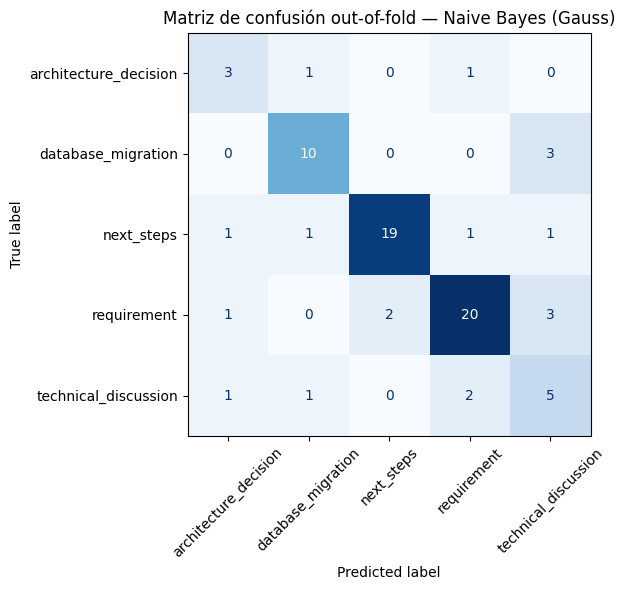

Segmentos mal clasificados: 19 de 76


,session_id,categoría real,predicción,texto
9,S08_ARCHITECTURE,architecture_decision,requirement,"Should we use a centralized vector database like Vertex AI Vector Search, or a local index for Reese data?"
40,S16_IMPLEMENTATION,architecture_decision,database_migration,The load balancer should route traffic to nearest regions using Global Anycast IP.
56,S23_REVIEW,database_migration,technical_discussion,The data migration from legacy CRM database has been completed with zero downtime.
10,S08_ARCHITECTURE,database_migration,technical_discussion,Let's verify that the migrated Spanner tables have their primary keys chosen to avoid hot-spotting.
12,S09_SECURITY,database_migration,technical_discussion,Using Cloud SQL for PostgreSQL is a cost-effective choice for our metadata storage needs.
0,S02_ARCHITECTURE,next_steps,database_migration,La arquitectura utilizará almacenamiento de objetos...
16,S10_IMPLEMENTATION,next_steps,architecture_decision,I will share the architecture slides with Jorge Muñoz for final director-level sign-off.
29,S13_DISCOVERY,next_steps,requirement,Next step is to perform a load test on the retrieval pipeline using synthetic user profiles.
27,S13_DISCOVERY,next_steps,technical_discussion,Let's organize a workshop on the CRISP-ML(Q) pipeline for the client development team.
42,S17_REVIEW,requirement,technical_discussion,The pipeline must ingest hourly updates from the PostgreSQL database without causing performance degradation.


In [9]:
# Desempeño por categoría del modelo final con predicciones out-of-fold de la validación anidada:
# cada uno de los 76 segmentos se predice con un modelo ajustado sin ese segmento ni su sesión.
pred_final = resultados_anidados[nombre_final]['oof']
f1_oof = f1_score(y, pred_final, average='macro')
print(f'F1-Macro out-of-fold sobre los 76 segmentos: {f1_oof:.3f} (meta {META_NEGOCIO:.2f}, baseline {F1_BASELINE:.3f})')
print(classification_report(y, pred_final, labels=CLASES, zero_division=0))

fig, ax = plt.subplots(figsize=(7.5, 6))
ConfusionMatrixDisplay.from_predictions(y, pred_final, labels=CLASES, ax=ax, xticks_rotation=45,
                                        cmap='Blues', colorbar=False)
ax.set_title(f'Matriz de confusión out-of-fold — {nombre_final}')
plt.tight_layout()
plt.show()

errores = df_modelo.loc[pred_final != y, ['session_id', 'expected_category', 'text_clean']].copy()
errores.insert(2, 'predicción', pred_final[pred_final != y])
errores = errores.rename(columns={'expected_category': 'categoría real', 'text_clean': 'texto'})
print(f'Segmentos mal clasificados: {len(errores)} de {len(y)}')
display(errores.sort_values('categoría real'))

**Lectura de los errores (*out-of-fold*):**
- **Decisiones de arquitectura (2 de 5 fallidas):** se confunden con requisitos y con migración de base de datos. Por ejemplo, "Should we use a centralized vector database... or a local index" es una **pregunta abierta** y no una decisión tomada, y "The load balancer should route traffic..." comparte la forma "should" con los requisitos. Distinguir una decisión de una propuesta requiere entender el contexto de la conversación, que es justo lo que se espera de Gemini.
- **Decisiones inventadas:** 3 de los 6 segmentos que el modelo marca como decisión de arquitectura no lo son: un siguiente paso ("I will share the architecture slides... for final director-level sign-off"), un requisito ("The system must comply with regional data residency guidelines...") y una discusión técnica ("We are seeing some prompt injection vulnerabilities..."). Es el error más costoso para el TDD y la razón por la que la precisión de esta clase (0.50) pesa en la selección.
- **Discusión técnica frente a requisitos y siguientes pasos:** varios segmentos etiquetados como discusión técnica son, por su forma, propuestas o acuerdos ("We should configure Pub/Sub dead-letter queues...", "Let's use Database Migration Service..."). Parte del error viene de una **frontera ambigua en las propias etiquetas** del corpus sintético. Para el TDD conviene definir con el especialista criterios explícitos de qué cuenta como decisión.
- **Calidad de etiquetas:** `SEG008` está en español, truncado ("La arquitectura utilizará almacenamiento de objetos...") y etiquetado como siguiente paso aunque describe una decisión de arquitectura. Lo dejamos en el corpus por consistencia con el Avance 3 y lo registramos como pendiente de revisión.

### 4.2 Control del efecto de plantilla

La retroalimentación del Avance 2 señaló que las plantillas del corpus inflan los indicadores léxicos. Para medir cuánto depende el modelo de ellas, calculamos para cada segmento la **similitud coseno (TF-IDF) con el segmento más parecido de las sesiones de entrenamiento** de su fold y comparamos la exactitud del modelo final por terciles de similitud.

In [10]:
# Control del efecto de plantilla (observación del Avance 2): ¿el modelo acierta más cuando el segmento
# se parece mucho a uno de entrenamiento? Para cada segmento se mide la similitud coseno (TF-IDF) con el
# segmento más parecido de las OTRAS sesiones usadas para entrenar en su fold.
from sklearn.metrics.pairwise import linear_kernel
similitud = pd.Series(index=y.index, dtype=float)
for tr, te in SPLITS_REP1:
    vec = TfidfVectorizer(ngram_range=(1, 2), stop_words='english').fit(X['text_clean'].iloc[tr])
    sims = linear_kernel(vec.transform(X['text_clean'].iloc[te]), vec.transform(X['text_clean'].iloc[tr]))
    similitud.iloc[te] = sims.max(axis=1)

control = pd.DataFrame({'similitud': similitud, 'acierto': (pred_final == y)})
control['grupo'] = pd.qcut(control['similitud'], 3, labels=['baja', 'media', 'alta'])
resumen_plantilla = control.groupby('grupo', observed=True).agg(
    Segmentos=('acierto', 'size'),
    **{'Similitud mín.': ('similitud', 'min'), 'Similitud máx.': ('similitud', 'max'),
       'Exactitud del modelo final': ('acierto', 'mean')})
display(resumen_plantilla.round(3))

,Segmentos,Similitud mín.,Similitud máx.,Exactitud del modelo final
grupo,,,,
baja,26,0.000,0.382,0.50
media,25,0.382,0.870,0.80
alta,25,0.871,1.000,0.96


**Resultado:** la exactitud pasa de **0.50** en los segmentos poco parecidos a los de entrenamiento a **0.80** en los de similitud media y **0.96** en los casi idénticos. El modelo acierta sobre todo cuando ya vio una frase casi igual en otra sesión; con formulaciones nuevas acierta solo la mitad de las veces.

**Implicación:** aun después de quitar duplicados exactos, el desempeño medido está **inflado por plantillas casi repetidas**, y con reuniones reales, donde cada consultor y cliente se expresan distinto, debe esperarse un resultado más cercano al del tercil bajo. Es la evidencia más directa de por qué un clasificador entrenado con pocos ejemplos sintéticos no basta para el Agente Analista.

### 4.3 Interpretabilidad del modelo final

Para un consultor, saber *por qué* un segmento se mandó a la sección de decisiones es parte de la trazabilidad que pide el proyecto. En Naive Bayes, cada categoría tiene un perfil promedio de términos; la tabla muestra los términos cuyo peso en la categoría más supera al de las demás.

In [11]:
# Interpretabilidad del modelo final: qué términos distinguen cada categoría (solo variables de texto).
modelo_ajustado = clone(modelo_final).fit(X, y)
prep, est = modelo_ajustado.named_steps['preparacion'], modelo_ajustado.named_steps['modelo']
nombres = prep.get_feature_names_out()
es_texto = np.array([n.startswith('texto__') for n in nombres])
terminos = np.array([n.replace('texto__', '') for n in nombres])[es_texto]
if hasattr(est, 'theta_'):      # Naive Bayes: TF-IDF medio de la clase menos el promedio de las demás clases
    pesos = est.theta_[:, es_texto]
    pesos = pesos - (pesos.sum(axis=0) - pesos) / (len(est.classes_) - 1)
elif hasattr(est, 'coef_') and est.coef_.shape[0] == len(est.classes_):
    pesos = est.coef_[:, es_texto]
else:
    pesos = None
if pesos is not None:
    tabla = pd.DataFrame({c: terminos[np.argsort(pesos[i])[::-1][:8]] for i, c in enumerate(est.classes_)})
    print('Términos que más distinguen cada categoría en el modelo final:')
    display(tabla)
elif hasattr(est, 'tree_'):
    print(export_text(est, feature_names=list(nombres), max_depth=4))
else:
    print(f'{nombre_final} no expone pesos por término; el análisis de errores es la herramienta de diagnóstico.')

Términos que más distinguen cada categoría en el modelo final:


,architecture_decision,database_migration,next_steps,requirement,technical_discussion
0,prosa,database replication,delivery,conversations,testing
1,deployment,seconds limits,team,curated multi,tables
2,load,replication,review,curated,service
3,vector,replication lag,schedule,contain,pipeline
4,need,limits,strategy doc,golden,semantic
5,multi,lag currently,deployment scalability,golden dataset,latency
6,strategy,lag,draft deployment,turn conversations,model
7,using,database,draft,dataset,prompt


**Lectura:** varios términos distintivos no describen la intención del segmento sino **entidades de las plantillas**. Por ejemplo, `prosa` (nombre de un cliente ficticio) es el término más asociado a decisiones de arquitectura, y en requisitos aparecen frases repetidas del generador ("curated", "contain"). Esto confirma el hallazgo de la sección 4.2: el modelo aprende a reconocer plantillas y nombres, no la noción de "decisión". Con datos reales, un término como el nombre del cliente sería una señal espuria.

In [12]:
mejor_inicial = df_results.iloc[0]
fila_final = df_finalistas.set_index('Modelo').loc[nombre_final]
print('Resumen para el reporte')
print(f'- Datos: {len(y)} segmentos únicos de {groups.nunique()} sesiones (misma limpieza que el Avance 3).')
print(f'- Referencias: azar {F1_AZAR:.3f} | baseline Random Forest del Avance 3 {F1_BASELINE:.3f} | meta de negocio {META_NEGOCIO:.2f}.')
print(f"- Mejor modelo sin ajustar: {mejor_inicial['Modelo']} ({mejor_inicial['F1-Macro (CV)']:.3f} ± {mejor_inicial['Desv. F1']:.3f}).")
for _, r in df_antes_despues.iterrows():
    print(f"- {r['Modelo']}: {r['F1 sin ajustar']:.3f} sin ajustar -> {r['F1 ajustado (CV anidada)']:.3f} ajustado (mejora {r['Mejora']:+.3f}, {r['Folds que mejoran']} folds).")
print(f"- Modelo final: {nombre_final}, F1-Macro {fila_final['F1-Macro (CV anidada)']:.3f} ± {fila_final['Desv. F1']:.3f} (CV anidada); "
      f"{'alcanza' if fila_final['F1-Macro (CV anidada)'] >= META_NEGOCIO else 'no alcanza'} la meta de {META_NEGOCIO:.2f}.")
print(f"- Decisión de arquitectura: precisión {fila_final['Precisión decisión arq.']:.2f}, recall {fila_final['Recall decisión arq.']:.2f} | recall de requisitos {fila_final['Recall requisitos']:.2f}.")

Resumen para el reporte
- Datos: 76 segmentos únicos de 25 sesiones (misma limpieza que el Avance 3).
- Referencias: azar 0.126 | baseline Random Forest del Avance 3 0.541 | meta de negocio 0.70.
- Mejor modelo sin ajustar: Naive Bayes (Gauss) (0.557 ± 0.099).
- Naive Bayes (Gauss): 0.557 sin ajustar -> 0.605 ajustado (mejora +0.048, 8 de 15 folds).
- Regresión Logística: 0.546 sin ajustar -> 0.561 ajustado (mejora +0.015, 6 de 15 folds).
- Modelo final: Naive Bayes (Gauss), F1-Macro 0.605 ± 0.138 (CV anidada); no alcanza la meta de 0.70.
- Decisión de arquitectura: precisión 0.50, recall 0.60 | recall de requisitos 0.77.


## 5. Conclusiones y relación con el proyecto

**Respuesta a la pregunta del avance.** Ningún modelo clásico individual alcanza la meta de F1-Macro ≥ 0.70 con este corpus, ni siquiera tras un ajuste amplio:

| Referencia o modelo | F1-Macro (validación agrupada por sesión) |
|---|---|
| Azar | 0.126 |
| Baseline Avance 3 (Random Forest) | 0.541 |
| Mejor modelo sin ajustar (Naive Bayes) | 0.557 |
| **Modelo final: Naive Bayes ajustado (CV anidada)** | **0.605** |
| Meta de negocio | 0.70 |

1. **Comparación:** seis algoritmos de familias distintas quedan en un rango estrecho (0.50–0.56, salvo KNN), dentro de la variabilidad entre sesiones. Cambiar de algoritmo no rompe el techo observado en el Avance 3.
2. **Ajuste:** con 900 configuraciones evaluadas en validación anidada, el ajuste mejora a Naive Bayes de forma moderada (+0.048) y a la Regresión Logística de forma marginal (+0.015). La diferencia entre la ganancia aparente (+0.13) y la real muestra por qué medimos con validación anidada.
3. **Modelo final:** Naive Bayes ajustado, elegido por la regla declarada: sin diferencia distinguible en F1-Macro, es el único candidato que identifica decisiones de arquitectura (precisión 0.50, recall 0.60) y confunde menos la discusión técnica.
4. **Limitaciones:** 76 segmentos sintéticos, 5 decisiones de arquitectura de 4 sesiones, etiquetas con fronteras ambiguas y fuerte efecto de plantilla (exactitud de 0.50 en segmentos poco parecidos a los de entrenamiento). Los resultados validan la metodología, no el desempeño con reuniones reales.

**Implicaciones para el Avance 5 y el flujo de agentes:**
- El **Naive Bayes ajustado queda como referencia mínima** que el clasificador con Gemini (*zero/few-shot*) debe superar, evaluado con las **mismas 15 particiones, la misma métrica y el mismo análisis por similitud y por categoría**, en especial la precisión en decisiones de arquitectura.
- Por su costo casi nulo, puede servir como **verificación de respaldo** en el Agente Analista: marcar para revisión humana los segmentos donde Gemini y el clasificador no coincidan sobre si hay una decisión.
- Antes de ampliar el corpus conviene **acordar con el especialista criterios explícitos** para distinguir decisión, propuesta y discusión técnica, y generar segmentos con **paráfrasis diversas** (no plantillas), aplicadas solo al entrenamiento.
- Falta la categoría de **riesgos y dependencias**, que la pregunta de negocio 2 del Avance 0 requiere y el corpus actual no contiene.

## 6. Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Google. (2026). Gemini [Modelo de lenguaje grande].<br>https://gemini.google.com/ | Explorar alternativas de clasificación y el uso de búsquedas de hiperparámetros | Secciones 2 y 3 (versión inicial del código) | Se ejecutó el notebook y se ajustaron respuestas e hiperparametros |
| OpenAI. (2026). ChatGPT [Modelo de lenguaje grande].<br>https://chatgpt.com/ | Organizar el preprocesamiento en `Pipeline` e incorporar la validación agrupada por sesión | Secciones 1.1 y 2 (versión inicial del código) | Revisión general de respuestas y ejecución de notebook |
| Anthropic. (2026). Claude (Claude Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.ai/ | Revisar la consistencia con los Avances 0–3 y la rúbrica; reestructurar el esquema de evaluación (validación estratificada y agrupada, validación anidada, control del efecto de plantilla); redactar borradores de interpretaciones | Secciones 0 a 5 | Se cotejaron las cifras citadas en el texto con las salidas guardadas. |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Jorge Muñoz Estrada | Elaboró el borrador inicial del avance con la propuesta: selección de los seis algoritmos, comparación inicial y ajuste de los dos mejores modelos. |
| Edgar Iván Ramírez | Ajustó el borrador al detectar fuga de información: el conjunto de prueba se usaba varias veces para validar. Reorganizó el flujo para que la selección y el ajuste usaran solo los datos de desarrollo y la prueba se utilizara una única vez al final. |
| Juan Pablo Carvajal | Revisó el avance contra la rúbrica, los Avances 0–3 y la retroalimentación del profesor. Identificó que los datos no seguían la limpieza del Avance 3 y que las conclusiones no coincidían con las salidas. Coordinó la reestructuración: datos de 76 segmentos, validación estratificada y agrupada por sesión, validación anidada, regla de selección con criterios del proyecto, análisis de errores y del efecto de plantilla, sección 0 y esta declaración. |

### Decisiones principales

<small><b>Decisión 1:</b> Modelar con los 76 segmentos únicos, con la misma limpieza del Avance 3</small>

- <small>Justificación: las 27 filas de relleno no contienen información de la categoría y las 36 frases duplicadas inflan la métrica por memorización, como demostró el Avance 3 (sección 3.6). Así los resultados son comparables con el baseline.</small>
- <small>Alternativa descartada y motivo: usar las 139 filas del Avance 2, porque mezcla copias de la misma frase entre entrenamiento y validación.</small>

<small><b>Decisión 2:</b> Estimar el desempeño con validación cruzada estratificada y agrupada por sesión (15 particiones) y medir el ajuste con validación anidada</small>

- <small>Justificación: con 76 segmentos, una partición fija de prueba deja muy pocos casos. La del Avance 3 no contenía ninguna decisión de arquitectura ni discusión técnica. La validación anidada separa la mejora real del sesgo de elegir entre muchas configuraciones.</small>
- <small>Alternativa descartada y motivo: una partición fija de prueba con `GridSearchCV`, porque no permite evaluar las clases críticas y reporta una mejora optimista (en este corpus, ≈0.06 puntos mayor que la real).</small>

<small><b>Decisión 3:</b> Elegir el modelo final con una regla que combina F1-Macro y criterios del proyecto</small>

- <small>Justificación: la diferencia de F1-Macro entre los dos candidatos fue menor que la variabilidad entre folds, así que se priorizó la precisión en decisiones de arquitectura (una decisión inventada daña la fidelidad del TDD). Por eso se eligió Naive Bayes.</small>
- <small>Alternativa descartada y motivo: elegir solo por el F1-Macro más alto, porque esa diferencia no es distinguible con este corpus y el otro candidato no reconoce ninguna decisión de arquitectura.</small>